# Assignment 2 Continuous-time Fourier series and transform

I denna notebook undersöks signaler som Fourier-serier och sambanden mellan tidsdomänet, frekvensdomänet och transformerna dem emellan.  

AI statement: Vi har ställt frågor till AI för att förstå uppgifterna och koppla de till lecture notes och föreläsningsslides. Vi har använt AI för att få hjälp med att felsöka koden efter matematiska fel som exempelvis division by zero, och lösa dessa fel. Vi har även använt AI för att använda np.sum på rätt sätt med olikdimensionerade matriser. 

# Uppgift 1a

Se graf nedan för den genererade signalen.

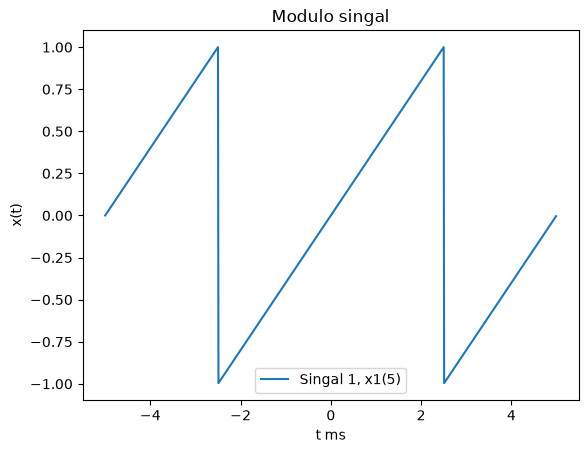

In [24]:
import numpy as np
import matplotlib.pyplot as plt

dt = 0.00001
t1 = np.arange(-0.005, 0.005, dt)

def x1(t):
    return -1 + (1/0.0025) * np.mod(t - 0.0025, 0.005)

plt.plot(t1 * 1000, x1(t1), label="Singal 1, x1(5)")
plt.title("Modulo singal")
plt.xlabel("t ms")
plt.ylabel("x(t)")
plt.legend()
plt.show()

# Uppgift 1b

Här gör vi flera approximationer med olika antal termer (N). Genom dessa approximationer kan vi se att vår graf närmar sig den faktiska signalen x(t) från uppgift 1a) mer och mer, desto fler termer (N) vi inkluderar i approximationen. Detta stämmer överens med teorin för Fourier-serier, som säger att en Fourier-serie närmar sig den ursprungliga signalen ju närmare termerna N är oändligheten. Alltså konvergerar Fourier-serien mot den ursprungliga signalen då $\lim_{N \to \infty}$. Detta stämmer överens med resultatet vi kan se när vi ritar upp graferna med den ursprungliga signalen x(t).


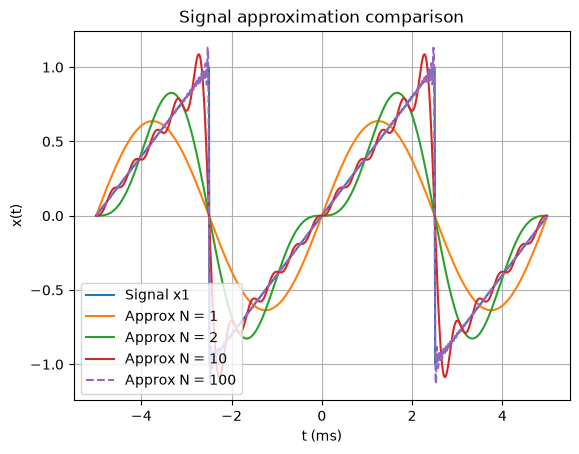

In [ ]:
N = np.array([1, 2, 10, 100])
T0 = 0.005 # 5 ms

def x_fourier(t, N_val):
    omega = 2 * np.pi / T0
    n = np.arange(-N_val, N_val + 1, 1)

    c = np.zeros(n.shape, dtype=complex)
    mask = (n != 0)
    c[mask] = ((-1.0)**n[mask]) * 1j * 1 / (n[mask] * np.pi)
        
    terms = c[:, None] * np.exp(1j * n[:, None] * omega * t[None, :]) # broadcast
    
    return np.real(np.sum(terms, axis=0))
    
approx1 = x_fourier(t1, N[0])
approx2 = x_fourier(t1, N[1])
approx3 = x_fourier(t1, N[2])
approx4 = x_fourier(t1, N[3])

fig, ax = plt.subplots()
ax.plot(t1*1000, x1(t1), label="Signal x1")
ax.plot(t1*1000, approx1, label="Approx N = 1")
ax.plot(t1*1000, approx2, label="Approx N = 2")
ax.plot(t1*1000, approx3, label="Approx N = 10")
ax.plot(t1*1000, approx4, label="Approx N = 100", linestyle="--")

ax.set_title("Signal approximation comparison")
ax.set_xlabel("t ms")
ax.set_ylabel("x(t)")
ax.legend()
ax.grid(True)
plt.show()

# Uppgift 1c

För att få fram rätt transformation för signalen använder vi oss av transformationstabellen, där vi använder transformen för T0-periodiska signaler. Sedan räknar vi ut signalens spektrum för det givna intervallet. I den plottade grafen för magnitudspektrumet kan vi se att amplituden är som högst vid de lägre frekvenserna, och att den minskar ju högre frekvensen blir. Vid $\omega=0$ är amplituden 0, vilket stämmer enligt den angivna definitionsmängden. Vi kan också se att signalens spektrum inte är kontinuerligt utan ett linjespektrum. 

I grafen för fasspektrumet kan vi se att fasen regelbundet skiftar mellan positiva och negativa värden. Vid $\omega$ = 0 är amplituden 0, likt magnitudspektrumet. Likt magnitudspektrumet är fasen inte kontinuerig utan definerad vid $n*\omega0$.

Den högsta amplituden finns vid de lägsta frekvenserna, vilket innebär att mest "energi"/styrka i signalen finns vid dessa frekvenser. Trots att amplituden är lägre vid de högre frekvenserna behövs dessa även för att beskriva signalen. Utan dessa skulle formen inte bli korrekt. Detta stämmer överens med vad vi såg i uppgift 1b). Med ett färre antal N fick vi en grundkurva som fångade en realtivt stor del av den ursprungliga signalens utseende, men ju fler N vi tar, desto bättre beskrivs ursprungskurvan. Detta visas i magnitud- och fasspektrumet, för de högre frekvenserna är amplituden låg, men om dessa lägre amplituder inkluderas i beräkningen för Fourier-serien får vi en bättre approximation av signalen. 

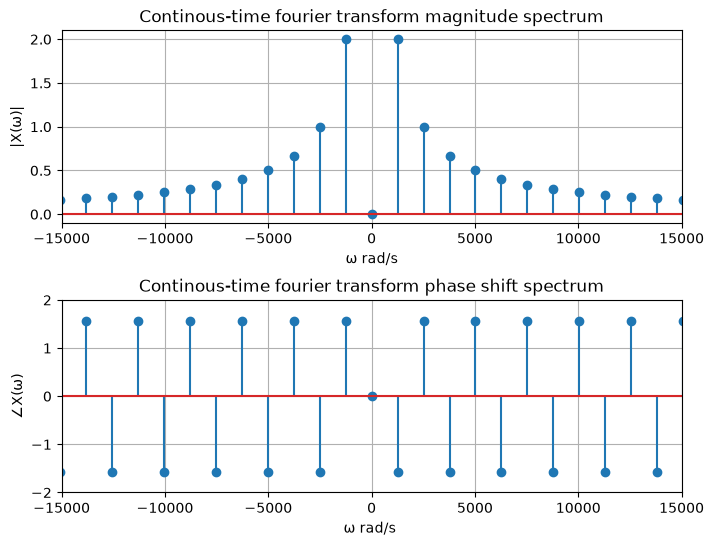

In [ ]:
def X(n):
    c = np.zeros(n.shape, dtype=complex)
    mask = (n != 0)
    c[mask] = ((-1.0)**n[mask]) * 1j * 1 / (n[mask] * np.pi)

    return 2*np.pi*c

w0 = 2 * np.pi / T0
M = 100
n = np.arange(-M, +M+1, 1)
wn = n * w0

Xn = X(n)

fig, ax = plt.subplots(2, 1, figsize=(8, 6))
ax[0].stem(wn, np.abs(Xn))
ax[1].stem(wn, np.angle(Xn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|X(ω)|")
ax[0].set_xlim(-15e3, 15e3)

ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠X(ω)")
ax[1].set_xlim(-15e3, 15e3)
ax[1].set_ylim(-2, 2)

ax[0].set_title("Fourier transform magnitude spectrum")
ax[1].set_title("Ffourier transform phase shift spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.4)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 2

Uttrycket för frekvenssvaret $H(\omega)$ för systemet med impulssvar $h(t) = \alpha^2te^{-\alpha t}u(t)$ beräknades utifrån transformen för real poles ur tabellen. Det gav oss uttrycket:
$$H(\omega) = \frac{\alpha^2}{(\alpha+j\omega)^2} $$

Utifrån vetskapen att $\vert{}Y(\omega)\vert{} = \vert{}H(\omega)\vert{}\vert{}X(\omega)\vert{}$ kan vi från plottningen läsa av hur frekvenssvaret påverkar inputsignaler för olika frekvenser.

Den plottade grafen för frekvenssvarets magnitudspektrum $|H(\omega)|$ visar att signaler dämpas mindre ju lägre frekvenskomponenten är. Vi ser på grafen att magnituden når 1.0 precis då $\omega=0$. Grafen över fasspektrumet visar att signaler fasfördröjs (bakåt/åt vänster) mer ju större negativ frekvensen är $\omega<0$, och fasförskjuts (framåt, åt höger) mer ju större positiv frekvensen är $\omega>0$. Ju lägre frekvensen är, desto mindre fasförskjuts den, eftersom staplarna närmare origo blir kortare och kortare.  

Att höga frekvenser filtreras bort medan låga frekvenser lämnas oförändrade innebär att systemet är ett lågpassfilter. Utsignalen $y(t)$ blir mjukare och rundare än insignalen $x(t)$.

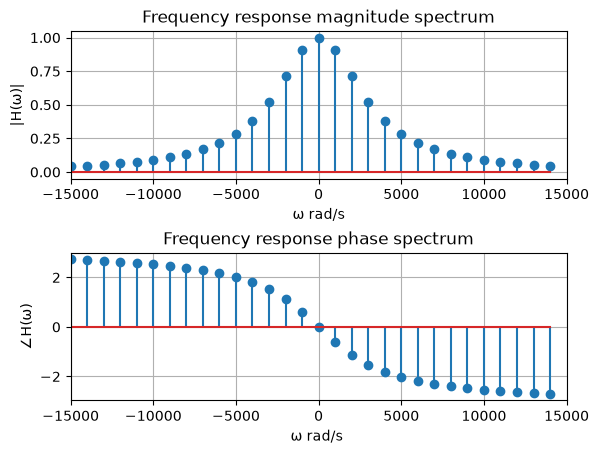

In [15]:
alfa = 1000 * np.pi

def u(t):
    return np.where(t >= 0, 1, 0)

def h(t):
    return alfa**2*t*np.exp(-alfa*t)*u(t)

def freq_resp(w):
    return (alfa / (alfa + 1j * w)) ** 2

dw = 1000
w = np.arange(-15e3, 15e3, dw)

Hn = freq_resp(w)

fig, ax = plt.subplots(2, 1)
ax[0].stem(w, np.abs(Hn))
ax[1].stem(w, np.angle(Hn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|H(ω)|")
ax[0].set_xlim(-15e3, 15e3)


ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠H(ω)")
ax[1].set_xlim(-15e3, 15e3)


ax[0].set_title("Frequency response magnitude spectrum")
ax[1].set_title("Frequency response phase spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.5)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 3a

Genom att multiplicera systemets frekvensrespons, $H(\omega)$, med insignalen $X(\omega)$ får vi frekvensspektrumet för utsignalen $Y(\omega)$. I grafen kan vi se sambanden mellan insignalen, frekvensresponsen, och utsignalen. 

Vi avläser att magnitudresponsen fungerar som en skalningsfaktor av insignalen för varje given frekvenskomponent, $$\vert{}Y(\omega)\vert{} = \vert{}H(\omega)\vert{} \cdot \vert{}X(\omega)\vert{}$$ Exempelvis har magnituden av utsignalen $|Y(\omega)|$ för $\omega=0$ inte förändrats eftersom insignalen $|X(0)|=0$ för denna frekvens. Samtidigt, för nästa frekvensstapel ser vi att magnituden för insignalen $|X(\omega)|=2$ dämpas av magnitudresponsen $|H(\omega)|\approx0.9$ och ger utsignalen $|Y(\omega)|\approx1.75$. 

För fasförsjutning gäller det istället att $$\angle Y(\omega) = \angle H(\omega) + \angle X(\omega)$$ Även detta kan vi avläsa i utsignalens frekvensspektrum där faserna förstärks eller dämpas beroende på om insignalens fasförskjutning är positiv eller negativ, samt om motsvarande fasrespons är positiv eller negativ. För exempelvis $\angle Y(0)$ förskjuts inte signalen något då både $\angle X(0) = 0$ och $\angle H(0) = 0$. För nästa frekvens sett från origo, förstärks fasförskjutningen för både den positiva och negativa frekvensen eftersom motsvarande fasrespons är positiv respektive negativ för de frekvenserna. 

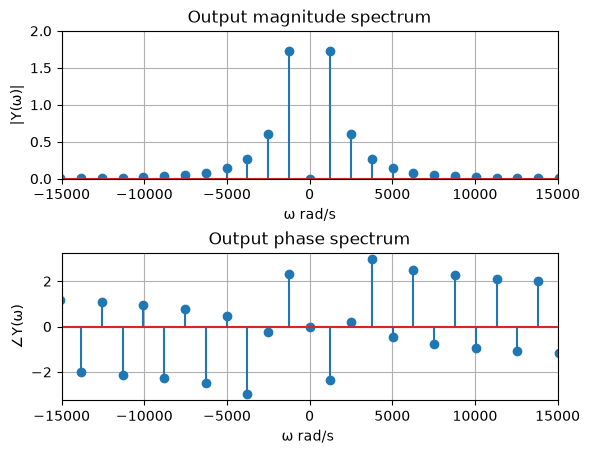

In [21]:
Hn_wn = freq_resp(wn)
Yn = Hn_wn * Xn

fig, ax = plt.subplots(2, 1)

ax[0].stem(wn, np.abs(Yn))
ax[1].stem(wn, np.angle(Yn))

ax[0].set_xlabel(" ω rad/s ")
ax[0].set_ylabel("|Y(ω)|")
ax[0].set_xlim(-15e3, 15e3)
ax[0].set_ylim(0, 2)


ax[1].set_xlabel(" ω rad/s  ")
ax[1].set_ylabel("∠Y(ω)")
ax[1].set_xlim(-15e3, 15e3)


ax[0].set_title("Output magnitude spectrum")
ax[1].set_title("Output phase spectrum")

ax[0].grid()
ax[1].grid()

plt.subplots_adjust(hspace=0.5)  # Ökar det vertikala avståndet mellan subplots

plt.show()

# Uppgift 3b

Eftersom utsignalen är periodisk med samma grundperiod T0 och den behåller samma frekvens i utsignal som i insignal uppfyller den kraven för att kunna skrivas i Fourier-serier, likt insignalen i uppgift 1b. 

Trunkeringsordningen i Fourier-serier bestämmer hur många frekvenskomponenter som tas med när man bygger signalen. Ju lägre N desto lägre frekvenser används. Det innebär att signalen "mjuknas av" för de lägre frekvenserna eftersom de höga, skarpa och snabba frekvenserna inte tas med. Detta kan vi observera i grafen där signalen för N=1 är mjuk medan signalen för N=100 har skarpare kanter, och också är mer lik den verkliga utsignalen. Detta observerades även i plottningen av insignalen i uppgift 1b. Det som skiljer insignalen från utsignalen är att insignalen har skarpa svängningar inom perioden. Dessa är inte med i utsignalen på grund av frekvensresponsen som fungerar som ett lågpassfilter plockar bort de höga frekvenserna som orskar de många svängningarna. 

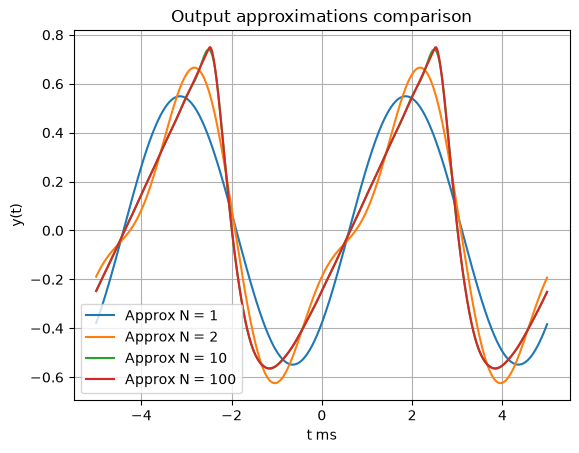

In [30]:
def output(t, N_val):
    omega = 2 * np.pi / T0
    n1 = np.arange(-N_val, N_val + 1, 1)

    indices = n1 + M
    Yn_subset = Yn[indices]

    exponent = (1j * n1[:, None] * omega * t[None, :])
    terms = Yn_subset[:, None] * np.exp(exponent)
    y = np.sum(terms, axis=0)
    return 1/(2 * np.pi) * np.real(y)

N = np.array([1, 2, 10, 100])

o_approx1 = output(t1, N[0])
o_approx2 = output(t1, N[1])
o_approx3 = output(t1, N[2])
o_approx4 = output(t1, N[3])

fig, ax = plt.subplots()

ax.plot(t1*1000,o_approx1, label="Approx N = 1")
ax.plot(t1*1000, o_approx2, label="Approx N = 2")
ax.plot(t1*1000, o_approx3, label="Approx N = 10")
ax.plot(t1*1000, o_approx4, label="Approx N = 100")

ax.set_title("Output approximations comparison")
ax.set_xlabel("t ms")
ax.set_ylabel("y(t)")
ax.legend()
ax.grid(True)

plt.show()
